# SVG

In Jupyter, a face, shape, wire, compound or sketch at the end of a cell shows itself as an SVG picture, without a
plot call. `ToSVG` returns the same picture as text, for a web page, a report or a file. Arcs and circles are exact
SVG arc commands in it, so the picture stays sharp at any zoom.

The example is the bell crank from [matplotlib](matplotlib.md), shown as the last line of the cell:

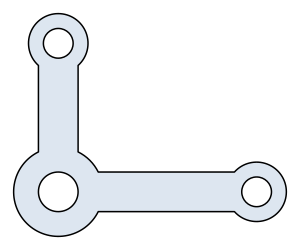

In [1]:
from IPython.display import SVG
import planex as px

bosses = [px.Circle((0, 0), 9).Face(), px.Circle((40, 0), 6).Face(), px.Circle((0, 30), 6).Face()]
arms = [px.Line((0, 0), (40, 0)).Offset(4), px.Line((0, 0), (0, 30)).Offset(4)]
holes = [px.Circle((0, 0), 4).Face(), px.Circle((40, 0), 3).Face(), px.Circle((0, 30), 3).Face()]
crank = px.Subtract([px.Unify(bosses + arms), *holes])
crank

`size` sets the larger side of the picture in pixels:

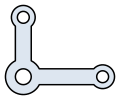

In [2]:
SVG(crank.ToSVG(size=120))

## Exact arcs

The arcs of the bosses and the round ends of the arms are single SVG arc commands, not polylines, which keeps the text
short:

In [3]:
svg = crank.ToSVG()
print(svg.count("A "), "arc commands,", len(svg), "characters")

26 arc commands, 1243 characters


## To a file

The text is written to a file like any string:

In [4]:
with open("bell-crank.svg", "w") as f:
    f.write(crank.ToSVG(size=600))

## Large objects

Above `px.config.max_preview_edges` edges, 5000 by default, an object shows its text instead of the picture, which
keeps notebooks fast. The limit can be raised for the session:

In [5]:
px.config.max_preview_edges = 20000